# COVID-19 Natural Experiment: Three-Period Analysis

Splits the corpus into three periods using the WHO COVID-19 pandemic definition:
- Pre-pandemic: before January 30, 2020 (WHO declared Public Health Emergency)
- During pandemic: January 30, 2020 to May 5, 2023 (WHO ended emergency status)
- Post-pandemic: after May 5, 2023

Compares mean factuality scores across all three jurisdictions in each period.

In [6]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

REPO = '/Users/caprice/MiscellaneousProjects/legislative-health-factuality'
os.makedirs(f'{REPO}/figures', exist_ok=True)

# WHO COVID-19 pandemic period
# Source: WHO Director-General declared PHEIC Jan 30, 2020
#         WHO ended emergency status May 5, 2023
COVID_START = '2020-01-30'
COVID_END   = '2023-05-05'

def get_period(date_str):
    if date_str < COVID_START:
        return 'Pre-pandemic'
    elif date_str <= COVID_END:
        return 'During pandemic'
    else:
        return 'Post-pandemic'

print(f'COVID period: {COVID_START} to {COVID_END}')
print('Source: WHO PHEIC declaration and termination')

COVID period: 2020-01-30 to 2023-05-05
Source: WHO PHEIC declaration and termination


In [7]:
# ── Load factuality scores for all three jurisdictions ────────────────────────

results = {}

# US
with open(f'{REPO}/data/dbpedia_pipeline/us/factuality_scores.json') as f:
    us_scores = json.load(f)

us_rows = []
for date, v in us_scores.items():
    if v['total_sentences'] > 0:
        us_rows.append({
            'date': date,
            'period': get_period(date),
            'factuality': v['factuality_score'],
            'jurisdiction': 'US House'
        })
us_df = pd.DataFrame(us_rows)

# Ontario
with open(f'{REPO}/data/dbpedia_pipeline/ontario/factuality_scores_per_bill.json') as f:
    ont_scores = json.load(f)
with open(f'{REPO}/data/canada/ontario/ontario_bill_index.json') as f:
    ont_index = json.load(f)

ont_rows = []
for bill_key, v in ont_scores.items():
    dates = ont_index.get(bill_key, {}).get('dates', [])
    if not dates: continue
    date = dates[-1]
    if v.get('factuality_score') is not None:
        ont_rows.append({
            'date': date,
            'period': get_period(date),
            'factuality': v['factuality_score'],
            'jurisdiction': 'Ontario LA'
        })
ont_df = pd.DataFrame(ont_rows)

# Quebec
with open(f'{REPO}/data/dbpedia_pipeline/quebec/factuality_scores.json') as f:
    qc_scores = json.load(f)

qc_rows = []
for date, v in qc_scores.items():
    if v['total_sentences'] > 0:
        qc_rows.append({
            'date': date,
            'period': get_period(date),
            'factuality': v['factuality_score'],
            'jurisdiction': 'Quebec NA'
        })
qc_df = pd.DataFrame(qc_rows)

# Combine
all_df = pd.concat([us_df, ont_df, qc_df], ignore_index=True)

print('Data loaded:')
for j in ['US House', 'Ontario LA', 'Quebec NA']:
    sub = all_df[all_df['jurisdiction'] == j]
    for p in ['Pre-pandemic', 'During pandemic', 'Post-pandemic']:
        n = len(sub[sub['period'] == p])
        mean = sub[sub['period'] == p]['factuality'].mean()
        print(f'  {j} {p}: n={n}, mean={mean:.4f}' if n > 0 else f'  {j} {p}: n=0')

Data loaded:
  US House Pre-pandemic: n=379, mean=0.2098
  US House During pandemic: n=42, mean=0.1824
  US House Post-pandemic: n=20, mean=0.1690
  Ontario LA Pre-pandemic: n=241, mean=0.1007
  Ontario LA During pandemic: n=42, mean=0.1035
  Ontario LA Post-pandemic: n=46, mean=0.0970
  Quebec NA Pre-pandemic: n=2036, mean=0.1382
  Quebec NA During pandemic: n=200, mean=0.1069
  Quebec NA Post-pandemic: n=212, mean=0.1124


In [8]:
# ── Summary table ─────────────────────────────────────────────────────────────

summary = all_df.groupby(['jurisdiction', 'period'])['factuality'].agg(['mean','count','std']).reset_index()
summary.columns = ['Jurisdiction', 'Period', 'Mean Factuality', 'N Bills', 'Std Dev']
summary['Mean Factuality'] = summary['Mean Factuality'].round(4)
summary['Std Dev'] = summary['Std Dev'].round(4)

period_order = ['Pre-pandemic', 'During pandemic', 'Post-pandemic']
juris_order  = ['US House', 'Ontario LA', 'Quebec NA']
summary['Period'] = pd.Categorical(summary['Period'], categories=period_order, ordered=True)
summary['Jurisdiction'] = pd.Categorical(summary['Jurisdiction'], categories=juris_order, ordered=True)
summary = summary.sort_values(['Jurisdiction', 'Period'])

print(summary.to_string(index=False))

Jurisdiction          Period  Mean Factuality  N Bills  Std Dev
    US House    Pre-pandemic           0.2098      379   0.1057
    US House During pandemic           0.1824       42   0.0785
    US House   Post-pandemic           0.1690       20   0.0929
  Ontario LA    Pre-pandemic           0.1007      241   0.0213
  Ontario LA During pandemic           0.1035       42   0.0188
  Ontario LA   Post-pandemic           0.0970       46   0.0184
   Quebec NA    Pre-pandemic           0.1382     2036   0.0438
   Quebec NA During pandemic           0.1069      200   0.0377
   Quebec NA   Post-pandemic           0.1124      212   0.0351


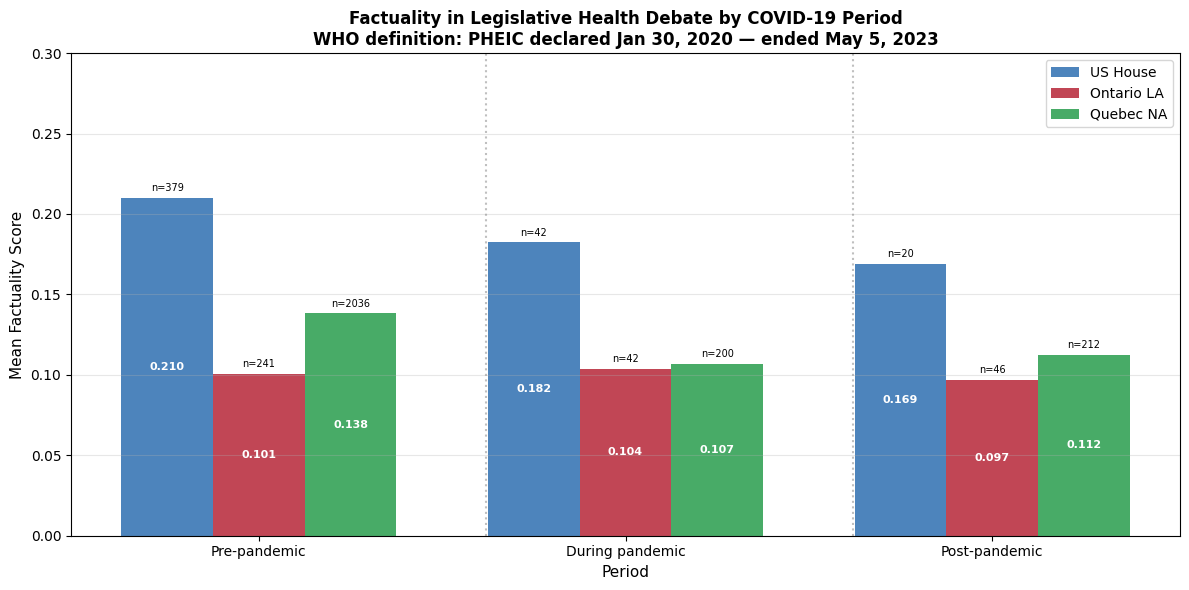

Saved to figures/covid_three_period.png


In [9]:
# ── FIGURE 1: Grouped bar chart ───────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 6))

period_order = ['Pre-pandemic', 'During pandemic', 'Post-pandemic']
juris_order  = ['US House', 'Ontario LA', 'Quebec NA']
colors       = ['#2166AC', '#B2182B', '#1A9641']

x = np.arange(len(period_order))
width = 0.25

for i, (juris, color) in enumerate(zip(juris_order, colors)):
    means = []
    ns = []
    for p in period_order:
        sub = all_df[(all_df['jurisdiction'] == juris) & (all_df['period'] == p)]
        means.append(sub['factuality'].mean() if len(sub) > 0 else 0)
        ns.append(len(sub))
    
    bars = ax.bar(x + i*width, means, width, label=juris, color=color, alpha=0.8)
    
    # Add n labels on bars
    for bar, n, mean in zip(bars, ns, means):
        if n > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                    f'n={n}', ha='center', va='bottom', fontsize=7, color='black')
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                    f'{mean:.3f}', ha='center', va='center', fontsize=8,
                    color='white', fontweight='bold')

ax.set_xlabel('Period', fontsize=11)
ax.set_ylabel('Mean Factuality Score', fontsize=11)
ax.set_title(
    'Factuality in Legislative Health Debate by COVID-19 Period\n'
    'WHO definition: PHEIC declared Jan 30, 2020 — ended May 5, 2023',
    fontsize=12, fontweight='bold'
)
ax.set_xticks(x + width)
ax.set_xticklabels(period_order, fontsize=10)
ax.set_ylim(0, 0.30)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Add vertical line between pre and during
ax.axvline(x=0.87, color='gray', linestyle=':', alpha=0.5)
ax.axvline(x=1.87, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(f'{REPO}/figures/covid_three_period.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/covid_three_period.png')

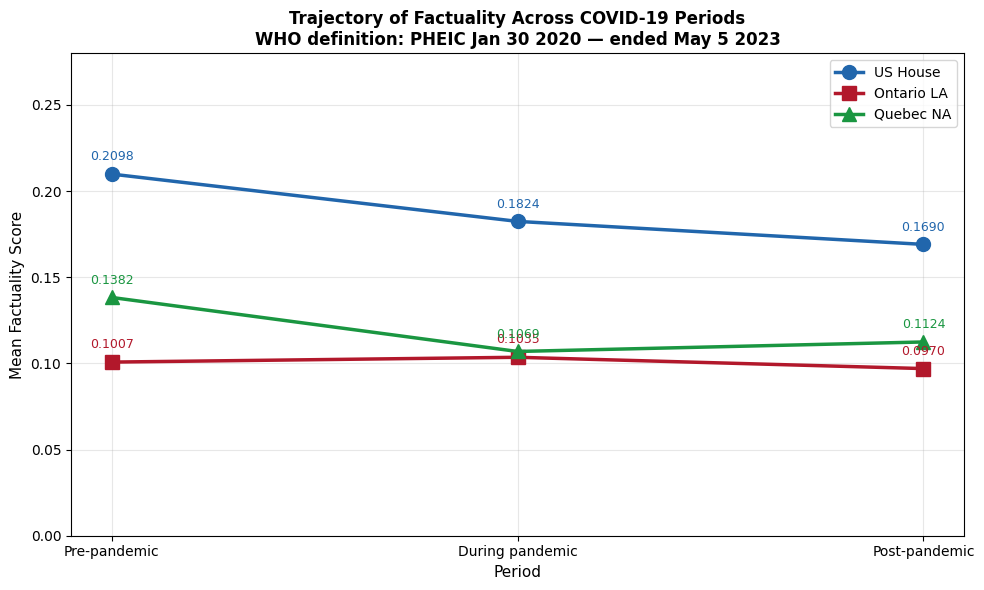

Saved to figures/covid_trajectory.png


In [10]:
# ── FIGURE 2: Change from pre to during to post ───────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))

colors = {'US House': '#2166AC', 'Ontario LA': '#B2182B', 'Quebec NA': '#1A9641'}
markers = {'US House': 'o', 'Ontario LA': 's', 'Quebec NA': '^'}

for juris in juris_order:
    means = []
    for p in period_order:
        sub = all_df[(all_df['jurisdiction'] == juris) & (all_df['period'] == p)]
        means.append(sub['factuality'].mean() if len(sub) > 0 else None)
    
    ax.plot(period_order, means, color=colors[juris], linewidth=2.5,
            marker=markers[juris], markersize=10, label=juris)
    
    # Annotate values
    for p, m in zip(period_order, means):
        if m is not None:
            ax.annotate(f'{m:.4f}', (p, m), textcoords='offset points',
                       xytext=(0, 10), ha='center', fontsize=9, color=colors[juris])

ax.set_xlabel('Period', fontsize=11)
ax.set_ylabel('Mean Factuality Score', fontsize=11)
ax.set_title(
    'Trajectory of Factuality Across COVID-19 Periods\n'
    'WHO definition: PHEIC Jan 30 2020 — ended May 5 2023',
    fontsize=12, fontweight='bold'
)
ax.set_ylim(0, 0.28)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{REPO}/figures/covid_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/covid_trajectory.png')